# 03 · Banded Newton and the cost of implicit steps

An implicit step solves a nonlinear system the size of the grid. Done carelessly - a dense Jacobian by n
function evaluations, a dense LU of n³/3 flops, every step - it costs more than the explicit method it was
meant to replace. Done with the structure of the method of lines it costs almost nothing: the Jacobian has the
band of the stencil, a banded LU costs n b², a finite-difference Jacobian needs b + 1 evaluations by colouring
the columns, and one Jacobian serves many steps. This notebook shows each of these ideas working, and what
the Newton iteration does when the Jacobian goes stale.

**What you will learn**
- recognise the band structure of a method-of-lines Jacobian
- compute a banded Jacobian by column colouring
- use banded LU and know its cost
- explain the modified Newton iteration and when the Jacobian must be refreshed

**Before you start:** notebooks 00 and 02  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engmolines is missing): install it from GitHub
    import engmolines
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engmolines"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import linalg as sla
from engmolines import grids, boundary as bc, operators as op, integrators as ti, stencils as st, linalg as la, problems as pr
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The Jacobian has the band of the stencil

Jacobian (31, 31): nonzeros only on the diagonals [-1, 0, 1]


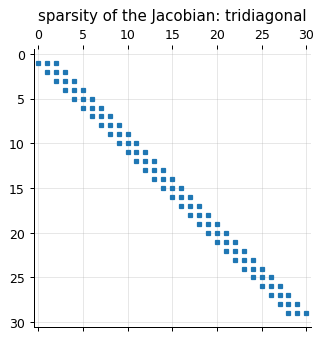

In [2]:
g = grids.uniform(0, 1, 30)
f = lambda u: op.diffusion(u, g, lambda x, u: 1 + u, bc.Dirichlet(1.0), bc.Dirichlet(0.0))    # noqa: E731, nonlinear conductivity
u = np.linspace(1, 0, 31)
J = la.dense_jacobian(f, u)
nz = np.abs(J) > 1e-9
print(f"Jacobian {J.shape}: nonzeros only on the diagonals {sorted({int(j - i) for i, j in zip(*np.where(nz))})}")
plt.spy(nz, markersize=3); plt.title("sparsity of the Jacobian: tridiagonal"); plt.show()

Each grid point's rate depends only on itself and its stencil neighbours, so the Jacobian is banded with the
stencil's half-width: tridiagonal for the three-point Laplacian, pentadiagonal for five-point stencils, and
of band n for a 2-D grid of n × n points (notebook 12). A dense Jacobian of a 10⁴-point grid holds 10⁸ numbers,
all but 3×10⁴ of them zero.

## Colouring: b + 1 evaluations instead of n

In [3]:
Jb = la.banded_jacobian(f, u, 1, 1)
print(f"banded Jacobian storage {Jb.shape} (3 rows x n) from 3 function evaluations; max |difference| from the dense one: {np.max(np.abs(la.from_banded(Jb, 1, 1) - J)):.1e}")
D4 = st.diff_operator(g.x, 2, 4)
print(f"5-point stencil: band {D4.bandwidth} (the one-sided closures reach 3 points in) -> {sum(D4.bandwidth) + 1} evaluations")

banded Jacobian storage (3, 31) (3 rows x n) from 3 function evaluations; max |difference| from the dense one: 0.0e+00
5-point stencil: band (5, 5) (the one-sided closures reach 3 points in) -> 11 evaluations


Columns j, j + w, j + 2w, ... of a banded Jacobian (w = bandwidth) never share a row, so perturbing them
together in one function evaluation recovers all of them: w evaluations for the whole Jacobian, whatever n is
(Curtis, Powell and Reid, 1974). For a 2-D problem with band n this is n evaluations instead of n² - still
cheap.

## Banded LU: n b² flops instead of n³/3

In [4]:
for n in (100, 1000, 10000):
    for b in (1, 2, 10):
        print(f"n = {n:6d}, band {b:2d}: banded LU ~ {2 * n * b**2:.1e} flops, dense LU ~ {2 * n**3 / 3:.1e} flops ({2 * n**3 / 3 / (2 * n * b**2):.0e}x)")
ab = la.to_banded(np.eye(31) - 0.01 * J, 1, 1)
x = la.solve_banded(ab, 1, 1, np.ones(31))
print(f"\nour banded solve vs scipy.linalg.solve_banded: {np.max(np.abs(x - sla.solve_banded((1, 1), ab, np.ones(31)))):.1e}")

n =    100, band  1: banded LU ~ 2.0e+02 flops, dense LU ~ 6.7e+05 flops (3e+03x)
n =    100, band  2: banded LU ~ 8.0e+02 flops, dense LU ~ 6.7e+05 flops (8e+02x)
n =    100, band 10: banded LU ~ 2.0e+04 flops, dense LU ~ 6.7e+05 flops (3e+01x)
n =   1000, band  1: banded LU ~ 2.0e+03 flops, dense LU ~ 6.7e+08 flops (3e+05x)
n =   1000, band  2: banded LU ~ 8.0e+03 flops, dense LU ~ 6.7e+08 flops (8e+04x)
n =   1000, band 10: banded LU ~ 2.0e+05 flops, dense LU ~ 6.7e+08 flops (3e+03x)
n =  10000, band  1: banded LU ~ 2.0e+04 flops, dense LU ~ 6.7e+11 flops (3e+07x)
n =  10000, band  2: banded LU ~ 8.0e+04 flops, dense LU ~ 6.7e+11 flops (8e+06x)
n =  10000, band 10: banded LU ~ 2.0e+06 flops, dense LU ~ 6.7e+11 flops (3e+05x)

our banded solve vs scipy.linalg.solve_banded: 1.3e-15


Elimination inside a band never creates entries outside it (partial pivoting can widen the upper band to
lo + up, which the factorisation allows for), so the factorisation costs about 2 n b² flops and each solve
2 n (2b + 1): linear in n. The library's banded LU reproduces SciPy's to rounding.

## One Jacobian, many steps: the modified Newton iteration

In [5]:
p = pr.nonlinear_conductivity()
for h, label in ((0.005, "moderate steps"), (0.02, "large steps")):
    s = p.solve("bdf", h, order=2)
    print(f"{label} (h = {h}): {s.steps} steps, {s.newton_iterations} Newton iterations ({s.newton_iterations / s.steps:.1f} per step), {s.jacobian_evaluations} Jacobian evaluations; steady-state error {np.max(np.abs(s.y[-1] - p.exact(p.x))):.1e}")

moderate steps (h = 0.005): 400 steps, 1090 Newton iterations (2.7 per step), 4 Jacobian evaluations; steady-state error 1.4e-05
large steps (h = 0.02): 100 steps, 447 Newton iterations (4.5 per step), 5 Jacobian evaluations; steady-state error 2.0e+00


The Newton iteration keeps the factorised Jacobian from a previous step (a *modified* Newton method), which
converges linearly rather than quadratically but costs only one banded solve per iteration. The iteration
monitors its own convergence rate and refreshes the Jacobian - a new coloured evaluation and factorisation -
only when it slows below a threshold. On this nonlinear problem a handful of Jacobians serve hundreds of steps.

The large-step run is a warning. Its Newton iterations converged at every step and the integrator reported
success - yet the final "steady state" is wrong by 2: part of the solution went to u = −1, where the
conductivity 1 + u vanishes, a non-physical equilibrium of the discrete equations that a step of 0.02 from the
discontinuous start lands in. (At h = 0.05 Newton fails outright at the second step and the fixed-step
integrator says so.) An implicit step too large for the nonlinearity can converge to a spurious solution;
convergence of Newton is not evidence of accuracy, and a check against physics - here, that the conductivity
stays positive - is part of the method. The next cell shows what the convergence monitor sees.

In [6]:
newton = ti._Newton(lambda t, u: p.rhs(t, u), (1, 1))
y = p.y0.copy(); h = 0.005
newton.refresh(0.0, y, h)
z = y.copy(); rhs_ = y.copy()
print("modified Newton with the Jacobian frozen at the initial (discontinuous) state - step sizes:")
for k in range(8):
    G = z - h * p.rhs(h, z) - rhs_
    dz = newton._solve(-G); z += dz
    print(f"   iteration {k + 1}: |dz| = {np.max(np.abs(dz)):.2e}")
z = y.copy()
print("full Newton (Jacobian refreshed every iteration):")
for k in range(5):
    newton.refresh(h, z, h)
    G = z - h * p.rhs(h, z) - rhs_
    dz = newton._solve(-G); z += dz
    print(f"   iteration {k + 1}: |dz| = {np.max(np.abs(dz)):.2e}")

modified Newton with the Jacobian frozen at the initial (discontinuous) state - step sizes:
   iteration 1: |dz| = 1.88e+00
   iteration 2: |dz| = 4.01e+00
   iteration 3: |dz| = 2.26e+01
   iteration 4: |dz| = 6.54e+00
   iteration 5: |dz| = 3.30e+00
   iteration 6: |dz| = 2.93e+00
   iteration 7: |dz| = 1.94e+00
   iteration 8: |dz| = 1.10e+00
full Newton (Jacobian refreshed every iteration):
   iteration 1: |dz| = 1.88e+00
   iteration 2: |dz| = 8.86e-01
   iteration 3: |dz| = 1.33e-01
   iteration 4: |dz| = 4.74e-03
   iteration 5: |dz| = 6.43e-06


From the initial state - a hot end next to a cold body, where the conductivity doubles in the first step - the
Jacobian frozen at that state is useless: the iteration wanders and diverges, while full Newton converges
quadratically in five iterations. This is why the library's Newton monitors its rate and refreshes the
Jacobian as soon as convergence slows (or the iterate stops being finite): a coloured Jacobian costs a few
evaluations, far less than a failed step. After the transient the solution changes little per step and one
Jacobian lasts for hundreds of steps.

## Inside the algorithm: colouring by hand

In [7]:
f0 = f(u); Jc = np.zeros((31, 31)); h_ = 1e-7
for c in range(3):                               # three colours for a tridiagonal Jacobian
    cols = np.arange(c, 31, 3)
    up = u.copy(); up[cols] += h_
    df = (f(up) - f0) / h_
    for j in cols:
        for i in range(max(0, j - 1), min(31, j + 2)):
            Jc[i, j] = df[i]
print("coloured Jacobian vs dense:", f"{np.max(np.abs(Jc - J)):.1e}", "- from 3 evaluations instead of 31")

coloured Jacobian vs dense: 0.0e+00 - from 3 evaluations instead of 31


## Exercises
1. Measure the Jacobian evaluations and Newton iterations of `problems.porous_medium()` for BDF1, BDF2 and BDF4 at the same step. Which order is cheapest per unit of accuracy against the Barenblatt solution?
2. For a 2-D grid of n x n points the Jacobian band is n. Tabulate the banded LU cost 2 N b^2 (N = n^2) and the dense cost 2 N^3/3 for n = 16, 32, 64, 128, and the memory of the banded factor (2 b + 1) N numbers versus N^2.
3. **Implement it yourself:** write a banded LU without pivoting for a tridiagonal matrix (the Thomas algorithm) and use it inside a backward-Euler step of the heat equation; compare the step with `integrators.bdf(order=1)`.